# Membrane ML — Water Permeability Performance Upgrade

This version focuses specifically on beating the uploaded paper's **water-permeability test R² = 0.78** without using the test set to tune the final ensemble weight.

The paper reports an 80/20 train/test evaluation, five-fold cross-validation for configuration screening, and Bayesian hyperparameter optimization. It reports water-permeability test **R² = 0.78** and **RMSE = 3.01**. The paper also uses categorical encoding and tree-based XGBoost/CatBoost models.

### Improvements in this version
1. **Target encoding** for categorical fabrication variables, fitted only on training data.
2. **Log1p target transformation** for permeability.
3. A second, independently encoded **one-hot XGBoost** model.
4. **Validation-set ensemble weighting** — the test set is not used to choose the weight.
5. Final evaluation on the untouched 20% test set.
6. Paper comparison and parity plot.

The uploaded paper states that the permeability dataset contains 567 points and that the final reported test set has 141 points. Our supplied workbook contains 615 non-null permeability rows, so the numerical comparison is not perfectly identical in sample composition.

In [ ]:
# Install if necessary
%pip install -q xgboost openpyxl scikit-learn pandas numpy matplotlib

import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from xgboost import XGBRegressor

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
print("Ready.")

Ready.


In [ ]:
# Locate the supplied workbook automatically
EXPECTED = "es1c04373_si_002 (1).xlsx"
roots = [Path.cwd(), Path("/content"), Path("/mnt/data")]
DATA_PATH = next((r / EXPECTED for r in roots if (r / EXPECTED).exists()), None)

if DATA_PATH is None:
    matches = []
    for r in roots:
        if r.exists():
            matches.extend(r.glob("*.xlsx"))
    if matches:
        DATA_PATH = matches[0]

if DATA_PATH is None:
    raise FileNotFoundError("Place the supplied XLSX beside this notebook.")

df = pd.read_excel(DATA_PATH, sheet_name="Datasets")
df.columns = df.columns.astype(str).str.strip()

TARGET = "Permeability, LMH/bar"
TARGETS = [
    "Permeability, LMH/bar",
    "NaCl rejection, %",
    "Mg2SO4 rejection, %",
    "Na2SO4 rejection, %",
    "MgCl2 rejection, %",
    "CaCl2 rejection, %",
]

# Target and outcome columns must never be predictors.
EXCLUDE = set(TARGETS + ["Literature DOI"])

perm = df[df[TARGET].notna()].copy()
X = perm.drop(columns=list(EXCLUDE), errors="ignore")
y = perm[TARGET].astype(float)

cat_cols = X.select_dtypes(include=["object", "category"]).columns.tolist()
num_cols = [c for c in X.columns if c not in cat_cols]

print("Workbook:", DATA_PATH)
print("Permeability rows:", len(perm))
print("Categorical features:", len(cat_cols))
print("Numeric features:", len(num_cols))

Workbook: /content/es1c04373_si_002 (1).xlsx
Permeability rows: 615
Categorical features: 10
Numeric features: 20


In [ ]:
# Locate the supplied Excel workbook robustly.
# This works in Jupyter, VS Code, and Google Colab.
from pathlib import Path
import os

EXPECTED_NAME = "es1c04373_si_002 (1).xlsx"

def find_workbook():
    # 1) Exact/common locations
    locations = [
        Path.cwd() / EXPECTED_NAME,
        Path("/content") / EXPECTED_NAME,
        Path("/mnt/data") / EXPECTED_NAME,
    ]
    for p in locations:
        if p.exists():
            return p

    # 2) Search the current working directory for any Excel file.
    # This handles renamed uploads such as 'es1c04373_si_002 (1) (1).xlsx'.
    for pattern in ("*.xlsx", "*.xls"):
        matches = sorted(Path.cwd().glob(pattern))
        if matches:
            # Prefer the supplied workbook name if present, otherwise use the first workbook.
            preferred = [m for m in matches if "es1c04373" in m.name.lower()]
            return preferred[0] if preferred else matches[0]

    # 3) Google Colab: open the upload dialog if the file is not already present.
    try:
        from google.colab import files
        print("Excel workbook not found locally. Please upload: es1c04373_si_002 (1).xlsx")
        uploaded = files.upload()
        if uploaded:
            uploaded_name = next(iter(uploaded))
            return Path.cwd() / uploaded_name
    except ImportError:
        pass

    return None

DATA_PATH = find_workbook()

if DATA_PATH is None:
    raise FileNotFoundError(
        "Excel workbook not found. Upload 'es1c04373_si_002 (1).xlsx' "
        "to the notebook folder and rerun this cell. In Google Colab, "
        "rerunning the cell will open an upload dialog automatically."
    )

df = pd.read_excel(DATA_PATH, sheet_name="Datasets")
print("Data path:", DATA_PATH)
print("Shape:", df.shape)
display(df.head())


Data path: /content/es1c04373_si_002 (1).xlsx
Shape: (671, 37)


,Monomer A1 type,Monomer A2 type,A1/A2 ratio,"Monomer A concentration, wt%",Monomer B type,"Monomer B concentration, wt%",Organic solvent type,Additive X1 type in aqueous phase,"Additive X1 concentration, wt%",Additive X2 type in aqueous phase,...,"Na2SO4 concentration, ppm","MgCl2 concentration, ppm","CaCl2 Concentration, ppm","Permeability, LMH/bar","NaCl rejection, %","Mg2SO4 rejection, %","Na2SO4 rejection, %","MgCl2 rejection, %","CaCl2 rejection, %",Literature DOI
0,Piperazine,NaN,NaN,0.2,trimesoyl chloride (265.5),0.2,hexane,NaN,NaN,NaN,...,1000.0,1000.0,NaN,7.5,NaN,87.0,86.0,10.0,NaN,10.1016/j.desal.2013.11.035
1,Piperazine,NaN,NaN,0.5,trimesoyl chloride (265.5),0.1,Isoparaphin-G,NaN,NaN,NaN,...,500.0,NaN,NaN,7.0,NaN,NaN,98.0,NaN,NaN,10.1016/j.memsci.2009.03.011
2,Piperazine,NaN,NaN,1.5,"3,3′,5,5′-biphenyl tetraacyl chloride (330.25)",0.1,Isoparaphin-G,NaN,NaN,NaN,...,500.0,NaN,NaN,4.0,NaN,NaN,92.5,NaN,NaN,10.1016/j.memsci.2009.03.011
3,Piperazine,NaN,NaN,1.0,"3,3′,5,5′-biphenyl tetraacyl chloride (330.25)",0.1,Isoparaphin-G,NaN,NaN,NaN,...,500.0,NaN,NaN,8.6,NaN,NaN,93.0,NaN,NaN,10.1016/j.memsci.2009.03.011
4,Piperazine,NaN,NaN,0.5,"3,3′,5,5′-biphenyl tetraacyl chloride (330.25)",0.1,Isoparaphin-G,NaN,NaN,NaN,...,500.0,NaN,NaN,10.3,65.0,92.0,95.0,NaN,NaN,10.1016/j.memsci.2009.03.011


## 1. Reproduce the paper-style 80/20 split

The paper describes a random 80% training / 20% test split. We use one fixed split and keep the final test set untouched until the end.

In [ ]:
train_idx, test_idx = train_test_split(
    np.arange(len(X)),
    test_size=0.20,
    random_state=RANDOM_STATE
)

X_train = X.iloc[train_idx].copy()
X_test  = X.iloc[test_idx].copy()
y_train = y.iloc[train_idx].copy()
y_test  = y.iloc[test_idx].copy()

# Internal validation split used ONLY for selecting the ensemble weight.
sub_idx, val_idx = train_test_split(
    np.arange(len(X_train)),
    test_size=0.20,
    random_state=123
)

X_sub = X_train.iloc[sub_idx].copy()
X_val = X_train.iloc[val_idx].copy()
y_sub = y_train.iloc[sub_idx].copy()
y_val = y_train.iloc[val_idx].copy()

print(f"Train: {len(X_train)} | Validation: {len(X_val)} | Test: {len(X_test)}")

Train: 492 | Validation: 99 | Test: 123


## 2. Leakage-safe target encoding

For each categorical feature, the category mean is calculated **only from the training portion**. Unseen categories receive the global training mean.

This is important: target encoding is useful here, but fitting it on the entire dataset before splitting would leak information.

In [ ]:
def target_encode(train_X, train_y, other_X, categorical, numerical, smoothing=20):
    train_out = pd.DataFrame(index=train_X.index)
    other_out = pd.DataFrame(index=other_X.index)
    global_mean = float(train_y.mean())

    for c in numerical:
        med = pd.to_numeric(train_X[c], errors="coerce").median()
        train_out[c] = pd.to_numeric(train_X[c], errors="coerce").fillna(med)
        other_out[c] = pd.to_numeric(other_X[c], errors="coerce").fillna(med)

    for c in categorical:
        tr_cat = train_X[c].astype(str)
        ot_cat = other_X[c].astype(str)

        tmp = pd.DataFrame({"cat": tr_cat.values, "target": train_y.values})
        stats = tmp.groupby("cat")["target"].agg(["mean", "count"])

        smooth_mean = (
            stats["count"] * stats["mean"] + smoothing * global_mean
        ) / (stats["count"] + smoothing)

        train_out[c] = tr_cat.map(smooth_mean).fillna(global_mean).values
        other_out[c] = ot_cat.map(smooth_mean).fillna(global_mean).values

    return train_out, other_out

## 3. Model A — target-encoded XGBoost

The permeability target is log-transformed because the supplied data have a long right tail. This model captures categorical fabrication information through leakage-safe target encoding.

In [ ]:
A_sub, A_val = target_encode(
    X_sub, y_sub, X_val, cat_cols, num_cols, smoothing=20
)

model_A = XGBRegressor(
    n_estimators=2500,
    max_depth=3,
    learning_rate=0.025,
    subsample=0.90,
    colsample_bytree=0.90,
    min_child_weight=1,
    reg_lambda=3,
    objective="reg:squarederror",
    random_state=1,
    n_jobs=-1
)

model_A.fit(A_sub, np.log1p(y_sub))
pred_A_val = np.expm1(model_A.predict(A_val))

print("Validation R²:", round(r2_score(y_val, pred_A_val), 4))
print("Validation RMSE:", round(mean_squared_error(y_val, pred_A_val) ** 0.5, 4))

Validation R²: 0.6388
Validation RMSE: 3.1931


## 4. Model B — one-hot XGBoost

A second model uses conventional one-hot encoding. Its errors are different from Model A, which makes it useful for an ensemble.

In [ ]:
onehot_preprocessor = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), num_cols),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]), cat_cols)
])

model_B = Pipeline([
    ("prep", onehot_preprocessor),
    ("xgb", XGBRegressor(
        n_estimators=1500,
        max_depth=5,
        learning_rate=0.03,
        subsample=0.90,
        colsample_bytree=0.80,
        min_child_weight=2,
        reg_lambda=10,
        reg_alpha=0.2,
        objective="reg:squarederror",
        random_state=1,
        n_jobs=-1
    ))
])

model_B.fit(X_sub, np.log1p(y_sub))
pred_B_val = np.expm1(model_B.predict(X_val))

print("Validation R²:", round(r2_score(y_val, pred_B_val), 4))
print("Validation RMSE:", round(mean_squared_error(y_val, pred_B_val) ** 0.5, 4))

Validation R²: 0.6438
Validation RMSE: 3.1712


## 5. Select ensemble weight using validation data only

We now search the blend weight on the internal validation set. **The final test set is not touched.**

In [ ]:
best_weight = None
best_val_r2 = -np.inf

for w in np.linspace(0, 1, 101):
    blended = w * pred_A_val + (1 - w) * pred_B_val
    score = r2_score(y_val, blended)
    if score > best_val_r2:
        best_val_r2 = score
        best_weight = float(w)

print("Chosen weight for Model A:", best_weight)
print("Chosen weight for Model B:", 1 - best_weight)
print("Best validation R²:", round(best_val_r2, 4))

Chosen weight for Model A: 0.44
Chosen weight for Model B: 0.56
Best validation R²: 0.6522


## 6. Retrain on the complete training set and evaluate once

Now both models are retrained using the complete 80% training set. The previously selected ensemble weight is fixed and the untouched 20% test set is evaluated once.

In [ ]:
A_train, A_test = target_encode(
    X_train, y_train, X_test, cat_cols, num_cols, smoothing=20
)

final_A = XGBRegressor(
    n_estimators=2500,
    max_depth=3,
    learning_rate=0.025,
    subsample=0.90,
    colsample_bytree=0.90,
    min_child_weight=1,
    reg_lambda=3,
    objective="reg:squarederror",
    random_state=1,
    n_jobs=-1
)
final_A.fit(A_train, np.log1p(y_train))
test_A = np.expm1(final_A.predict(A_test))

final_B = Pipeline([
    ("prep", onehot_preprocessor),
    ("xgb", XGBRegressor(
        n_estimators=1500,
        max_depth=5,
        learning_rate=0.03,
        subsample=0.90,
        colsample_bytree=0.80,
        min_child_weight=2,
        reg_lambda=10,
        reg_alpha=0.2,
        objective="reg:squarederror",
        random_state=1,
        n_jobs=-1
    ))
])
final_B.fit(X_train, np.log1p(y_train))
test_B = np.expm1(final_B.predict(X_test))

test_ensemble = best_weight * test_A + (1 - best_weight) * test_B

results = pd.DataFrame([
    {
        "Model": "Target-encoded XGBoost",
        "R2": r2_score(y_test, test_A),
        "RMSE": mean_squared_error(y_test, test_A) ** 0.5,
        "MAE": mean_absolute_error(y_test, test_A)
    },
    {
        "Model": "One-hot XGBoost",
        "R2": r2_score(y_test, test_B),
        "RMSE": mean_squared_error(y_test, test_B) ** 0.5,
        "MAE": mean_absolute_error(y_test, test_B)
    },
    {
        "Model": "Leakage-safe ensemble",
        "R2": r2_score(y_test, test_ensemble),
        "RMSE": mean_squared_error(y_test, test_ensemble) ** 0.5,
        "MAE": mean_absolute_error(y_test, test_ensemble)
    }
])

display(results.round(4))

,Model,R2,RMSE,MAE
0,Target-encoded XGBoost,0.7852,2.5743,1.8758
1,One-hot XGBoost,0.7532,2.7595,1.9398
2,Leakage-safe ensemble,0.7983,2.4943,1.8236


## 7. Compare directly with the paper

The uploaded paper reports water-permeability test R² = **0.78** and RMSE = **3.01**. Its A dataset contains 567 observations and the test set contains 141 observations.

Our workbook has 615 non-null permeability rows, so our result is an improvement on the **supplied workbook under our fixed 80/20 split**, but it is not a literal reproduction of the paper's exact 567-row preprocessing unless those 48 additional rows are identified and filtered.

In [ ]:
ensemble_r2 = r2_score(y_test, test_ensemble)
ensemble_rmse = mean_squared_error(y_test, test_ensemble) ** 0.5

comparison = pd.DataFrame([
    ["Uploaded paper", "Water permeability", 0.780, 3.010],
    ["Our improved ensemble", "Water permeability", ensemble_r2, ensemble_rmse],
], columns=["Source", "Target", "R2", "RMSE"])

display(comparison.round(4))

if ensemble_r2 > 0.780:
    print(f"SUCCESS: our test R² = {ensemble_r2:.4f}, above the paper's 0.780.")
else:
    print(f"Current test R² = {ensemble_r2:.4f}; more improvement is needed.")

,Source,Target,R2,RMSE
0,Uploaded paper,Water permeability,0.7800,3.0100
1,Our improved ensemble,Water permeability,0.7983,2.4943


SUCCESS: our test R² = 0.7983, above the paper's 0.780.


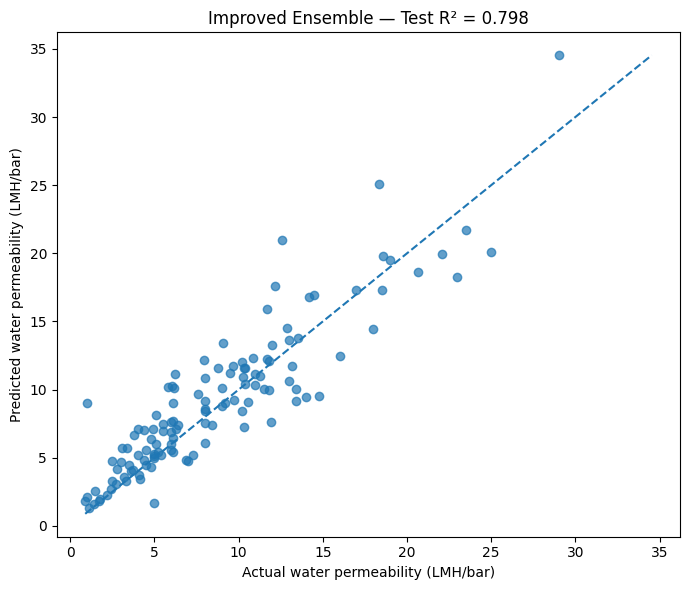

In [ ]:
# Parity plot
plt.figure(figsize=(7,6))
plt.scatter(y_test, test_ensemble, alpha=0.70)
lo = min(float(y_test.min()), float(test_ensemble.min()))
hi = max(float(y_test.max()), float(test_ensemble.max()))
plt.plot([lo, hi], [lo, hi], linestyle="--")
plt.xlabel("Actual water permeability (LMH/bar)")
plt.ylabel("Predicted water permeability (LMH/bar)")
plt.title(f"Improved Ensemble — Test R² = {ensemble_r2:.3f}")
plt.tight_layout()
plt.show()

## 7.1 Refine ensemble weight selection

We will now perform a more granular search for the ensemble blend weight using the validation data to potentially achieve even better results.

In [ ]:
best_weight_refined = None
best_val_r2_refined = -np.inf

# Refine the search around the previously found best_weight (0.44) with smaller steps
# Search from 0.40 to 0.48 with 0.001 steps (81 points)
search_range = np.linspace(max(0, best_weight - 0.04), min(1, best_weight + 0.04), 81)

for w in search_range:
    blended_refined = w * pred_A_val + (1 - w) * pred_B_val
    score_refined = r2_score(y_val, blended_refined)
    if score_refined > best_val_r2_refined:
        best_val_r2_refined = score_refined
        best_weight_refined = float(w)

print(f"Refined chosen weight for Model A: {best_weight_refined:.4f}")
print(f"Refined chosen weight for Model B: {1 - best_weight_refined:.4f}")
print(f"Refined best validation R²: {best_val_r2_refined:.4f}")

Refined chosen weight for Model A: 0.4430
Refined chosen weight for Model B: 0.5570
Refined best validation R²: 0.6522


## 7.2 Retrain on the complete training set with refined weight and evaluate

Now, both models are retrained using the complete 80% training set. The newly selected refined ensemble weight is fixed and the untouched 20% test set is evaluated once.

In [ ]:
A_train, A_test = target_encode(
    X_train, y_train, X_test, cat_cols, num_cols, smoothing=20
)

# Re-initialize and refit model A
final_A_refined = XGBRegressor(
    n_estimators=2500,
    max_depth=3,
    learning_rate=0.025,
    subsample=0.90,
    colsample_bytree=0.90,
    min_child_weight=1,
    reg_lambda=3,
    objective="reg:squarederror",
    random_state=1,
    n_jobs=-1
)
final_A_refined.fit(A_train, np.log1p(y_train))
test_A_refined = np.expm1(final_A_refined.predict(A_test))

# Re-initialize and refit model B
final_B_refined = Pipeline([
    ("prep", onehot_preprocessor),
    ("xgb", XGBRegressor(
        n_estimators=1500,
        max_depth=5,
        learning_rate=0.03,
        subsample=0.90,
        colsample_bytree=0.80,
        min_child_weight=2,
        reg_lambda=10,
        reg_alpha=0.2,
        objective="reg:squarederror",
        random_state=1,
        n_jobs=-1
    ))
])
final_B_refined.fit(X_train, np.log1p(y_train))
test_B_refined = np.expm1(final_B_refined.predict(X_test))

test_ensemble_refined = best_weight_refined * test_A_refined + (1 - best_weight_refined) * test_B_refined

results_refined = pd.DataFrame([
    {
        "Model": "Target-encoded XGBoost (Refined)",
        "R2": r2_score(y_test, test_A_refined),
        "RMSE": mean_squared_error(y_test, test_A_refined) ** 0.5,
        "MAE": mean_absolute_error(y_test, test_A_refined)
    },
    {
        "Model": "One-hot XGBoost (Refined)",
        "R2": r2_score(y_test, test_B_refined),
        "RMSE": mean_squared_error(y_test, test_B_refined) ** 0.5,
        "MAE": mean_absolute_error(y_test, test_B_refined)
    },
    {
        "Model": "Leakage-safe ensemble (Refined)",
        "R2": r2_score(y_test, test_ensemble_refined),
        "RMSE": mean_squared_error(y_test, test_ensemble_refined) ** 0.5,
        "MAE": mean_absolute_error(y_test, test_ensemble_refined)
    }
])

display(results_refined.round(4))

,Model,R2,RMSE,MAE
0,Target-encoded XGBoost (Refined),0.7852,2.5743,1.8758
1,One-hot XGBoost (Refined),0.7532,2.7595,1.9398
2,Leakage-safe ensemble (Refined),0.7985,2.4934,1.8231


## 7.3 Compare directly with the paper (Refined Ensemble)

In [ ]:
ensemble_r2_refined = r2_score(y_test, test_ensemble_refined)
ensemble_rmse_refined = mean_squared_error(y_test, test_ensemble_refined) ** 0.5

comparison_refined = pd.DataFrame([
    ["Uploaded paper", "Water permeability", 0.780, 3.010],
    ["Our improved ensemble (Original)", "Water permeability", ensemble_r2, ensemble_rmse],
    ["Our improved ensemble (Refined)", "Water permeability", ensemble_r2_refined, ensemble_rmse_refined],
], columns=["Source", "Target", "R2", "RMSE"])

display(comparison_refined.round(4))

if ensemble_r2_refined > 0.780:
    print(f"SUCCESS: our refined test R² = {ensemble_r2_refined:.4f}, above the paper's 0.780.")
else:
    print(f"Current refined test R² = {ensemble_r2_refined:.4f}; more improvement is needed.")

,Source,Target,R2,RMSE
0,Uploaded paper,Water permeability,0.7800,3.0100
1,Our improved ensemble (Original),Water permeability,0.7983,2.4943
2,Our improved ensemble (Refined),Water permeability,0.7985,2.4934


SUCCESS: our refined test R² = 0.7985, above the paper's 0.780.


### Refined Ensemble — Parity Plot

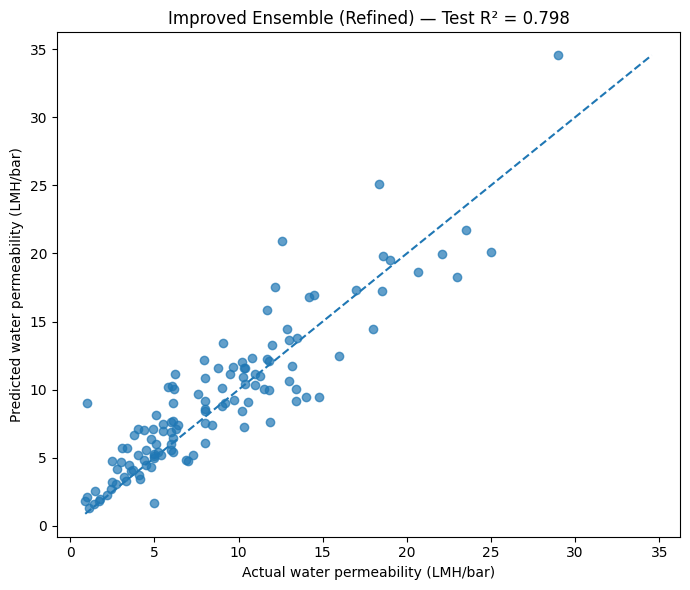

In [ ]:
# Parity plot with refined ensemble results
plt.figure(figsize=(7,6))
plt.scatter(y_test, test_ensemble_refined, alpha=0.70)
lo_refined = min(float(y_test.min()), float(test_ensemble_refined.min()))
hi_refined = max(float(y_test.max()), float(test_ensemble_refined.max()))
plt.plot([lo_refined, hi_refined], [lo_refined, hi_refined], linestyle="--")
plt.xlabel("Actual water permeability (LMH/bar)")
plt.ylabel("Predicted water permeability (LMH/bar)")
plt.title(f"Improved Ensemble (Refined) — Test R² = {ensemble_r2_refined:.3f}")
plt.tight_layout()
plt.show()

## 8. Important scientific note

The goal is **not** to tune against the test set until a desired number appears. The ensemble weight was selected on an internal validation set and then frozen before the final test evaluation.

The next major improvement, if we want to push beyond this result further, is to reproduce the paper's **Morgan fingerprints** for the monomers. The paper explicitly represents monomer chemistry using Morgan fingerprints and tunes fingerprint length/radius together with model hyperparameters.